In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import MDAnalysis as mda
from MDAnalysis.analysis.rdf import InterRDF

/Users/nate_schwindt/anaconda3/envs/aem/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# run inputs
start = 3000
stop = 4001
n_frames = 1000

# rdf inputs
r_range = (0.0, 10.0)
nbins = 200

# calculate some parameters from inputs
rdf_settings = {"bins": nbins, "range": r_range}
count, edges = np.histogram([-1], **rdf_settings)
bins = 0.5 * (edges[:-1] + edges[1:])
step = (stop - start) // n_frames

# initialize the dataframe to store the results
df = pd.DataFrame()
df['r_A'] = bins

In [3]:
# load in trajectory and make selections
u = mda.Universe('prod.tpr', 'prod_centered.xtc')

waters = u.select_atoms('type OW') # only water oxygen atoms
cations = u.select_atoms('resname NA')
anions = u.select_atoms('resname CL')

xlink_c = u.select_atoms(f'(type c) and (bonded type n)') # crosslinking carbon atoms
coo_c = u.select_atoms(f'(type c) and (not bonded type oh n)') # carbon in COO-

cooh_oh = u.select_atoms(f'type oh') # OH in COOH
amide_o = u.select_atoms(f'(type o) and (bonded group xlink_c)', xlink_c=xlink_c) # amide oxygen atoms
amide_n = u.select_atoms(f'(type n) and (bonded group xlink_c)', xlink_c=xlink_c) # amide nitrogen atoms
coo_o = u.select_atoms(f'(type o) and (bonded group coo_c)', coo_c=coo_c) # COO- oxygen atoms
nh2 = u.select_atoms(f'type nh') # amine nitrogen atoms
cl = u.select_atoms('(type cl) and (resname PA*)') # chlorine atoms on polymer
ca = u.select_atoms('type ca') # aromatic carbon atoms

# ortho-para ha
ca_bonded_n = u.select_atoms('(type ca) and (bonded type n)') 
tmp = u.select_atoms('(type ca) and (bonded group tmp)', tmp=ca_bonded_n)
ca_ortho_para = []
for atom in tmp:
    n_bonded_n = len([a for a in atom.bonded_atoms if a in ca_bonded_n])
    if n_bonded_n == 1:
        ca_ortho_para.append(atom)

ca_ortho_para = mda.AtomGroup(ca_ortho_para)
ha_ortho_para = u.select_atoms('(type ha) and (bonded group ca_ortho_para)', ca_ortho_para=ca_ortho_para)

pairs = [(cations, waters), (cations, anions), (cations, cations), (cations, coo_o), (cations, nh2), (cations, amide_o), (cations, amide_n), (cations, cl), (cations, ca), (cations, ha_ortho_para),
         (anions, waters),  (anions, anions), (anions, coo_o), (anions, nh2), (anions, amide_o), (anions, amide_n), (anions, cl), (anions, ca), (anions, ha_ortho_para),
         (coo_o, waters), (coo_o, coo_o), (coo_o, nh2), (coo_o, amide_o), (coo_o, amide_n), (coo_o, cl), (coo_o, ca), (coo_o, ha_ortho_para),
         (nh2, waters), (nh2, nh2), (nh2, amide_o), (nh2, amide_n), (nh2, cl), (nh2, ca), (nh2, ha_ortho_para),
         (amide_o, waters), (amide_o, amide_o), (amide_o, amide_n), (amide_o, cl), (amide_o, ca), (amide_o, ha_ortho_para),
         (amide_n, waters), (amide_n, amide_n), (amide_n, cl), (amide_n, ca), (amide_n, ha_ortho_para),
         (cl, waters), (cl, cl), (cl, ca), (cl, ha_ortho_para),
         (ca, waters), (ca, ca), (ca, ha_ortho_para),
         (ha_ortho_para, waters), (ha_ortho_para, ha_ortho_para),
         (waters, waters)]

names = [('cations', 'waters'), ('cations', 'anions'), ('cations', 'cations'), ('cations', 'coo_o'), ('cations', 'nh2'), ('cations', 'amide_o'), ('cations', 'amide_n'), ('cations', 'cl'), ('cations', 'ca'), ('cations', 'ha_ortho_para'),
         ('anions', 'waters'),  ('anions', 'anions'), ('anions', 'coo_o'), ('anions', 'nh2'), ('anions', 'amide_o'), ('anions', 'amide_n'), ('anions', 'cl'), ('anions', 'ca'), ('anions', 'ha_ortho_para'),
         ('coo_o', 'waters'), ('coo_o', 'coo_o'), ('coo_o', 'nh2'), ('coo_o', 'amide_o'), ('coo_o', 'amide_n'), ('coo_o', 'cl'), ('coo_o', 'ca'), ('coo_o', 'ha_ortho_para'),
         ('nh2', 'waters'), ('nh2', 'nh2'), ('nh2', 'amide_o'), ('nh2', 'amide_n'), ('nh2', 'cl'), ('nh2', 'ca'), ('nh2', 'ha_ortho_para'),
         ('amide_o', 'waters'), ('amide_o', 'amide_o'), ('amide_o', 'amide_n'), ('amide_o', 'cl'), ('amide_o', 'ca'), ('amide_o', 'ha_ortho_para'),
         ('amide_n', 'waters'), ('amide_n', 'amide_n'), ('amide_n', 'cl'), ('amide_n', 'ca'), ('amide_n', 'ha_ortho_para'),
         ('cl', 'waters'), ('cl', 'cl'), ('cl', 'ca'), ('cl', 'ha_ortho_para'),
         ('ca', 'waters'), ('ca', 'ca'), ('ca', 'ha_ortho_para'),
         ('ha_ortho_para', 'waters'), ('ha_ortho_para', 'ha_ortho_para'),
         ('waters', 'waters')]

In [4]:
def plot_rdf(df, x, y, ax=None):
    if ax is None:
        plt.figure(figsize=(4, 4))
        ax = plt.gca()
    ax.plot(df[x], df[y], label=y.removeprefix('rdf_'))
    ax.set_xlabel('r (Å)', fontsize=12)
    ax.set_ylabel('g(r)', fontsize=12)
    ax.set_xlim(2,8)
    ax.legend()
    ax.grid(alpha=0.25)
    return ax

## Generate all RDFs

In [5]:
for i,(pair,name) in enumerate(zip(pairs,names)):
    print(f"Calculating RDF for {name[0]} and {name[1]}: {i}/{len(pairs)}")
    rdf = InterRDF(pair[0], pair[1], nbins=nbins, range=r_range, exclusion_block=(1,1), verbose=False)
    rdf.run(start=start, stop=stop, step=step, backend='multiprocessing', n_workers=16)
    df[f'rdf_{name[0]}_{name[1]}'] = rdf.results.rdf
    df[f'count_{name[0]}_{name[1]}'] = rdf.results.count

df.to_csv('rdfs.csv', index=False)

Calculating RDF for cations and waters: 0/55
Calculating RDF for cations and anions: 1/55
Calculating RDF for cations and cations: 2/55
Calculating RDF for cations and coo_o: 3/55
Calculating RDF for cations and nh2: 4/55
Calculating RDF for cations and amide_o: 5/55
Calculating RDF for cations and amide_n: 6/55
Calculating RDF for cations and cl: 7/55
Calculating RDF for cations and ca: 8/55
Calculating RDF for cations and ha_ortho_para: 9/55
Calculating RDF for anions and waters: 10/55
Calculating RDF for anions and anions: 11/55
Calculating RDF for anions and coo_o: 12/55
Calculating RDF for anions and nh2: 13/55
Calculating RDF for anions and amide_o: 14/55
Calculating RDF for anions and amide_n: 15/55
Calculating RDF for anions and cl: 16/55
Calculating RDF for anions and ca: 17/55
Calculating RDF for anions and ha_ortho_para: 18/55
Calculating RDF for coo_o and waters: 19/55
Calculating RDF for coo_o and coo_o: 20/55
Calculating RDF for coo_o and nh2: 21/55
Calculating RDF for co

/Users/nate_schwindt/anaconda3/envs/aem/lib/python3.13/site-packages/MDAnalysis/analysis/rdf.py:401: RuntimeWarning: invalid value encountered in divide
  self.results.rdf = self.results.count / norm


Calculating RDF for cl and ca: 47/55


/Users/nate_schwindt/anaconda3/envs/aem/lib/python3.13/site-packages/MDAnalysis/analysis/rdf.py:401: RuntimeWarning: invalid value encountered in divide
  self.results.rdf = self.results.count / norm


Calculating RDF for cl and ha_ortho_para: 48/55


/Users/nate_schwindt/anaconda3/envs/aem/lib/python3.13/site-packages/MDAnalysis/analysis/rdf.py:401: RuntimeWarning: invalid value encountered in divide
  self.results.rdf = self.results.count / norm


... (8 outputs left out)

Calculating RDF for ha_ortho_para and ha_ortho_para: 53/55


/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_74740/448033837.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_{name[0]}_{name[1]}'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_74740/448033837.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_{name[0]}_{name[1]}'] = rdf.results.count


Calculating RDF for waters and waters: 54/55


/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_74740/448033837.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_{name[0]}_{name[1]}'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_74740/448033837.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_{name[0]}_{name[1]}'] = rdf.results.count
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_74740/448033837.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame

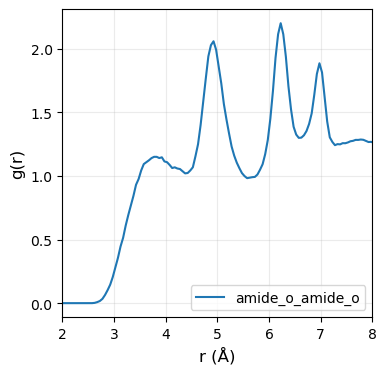

In [6]:
plot_rdf(df, 'r_A', 'rdf_amide_o_amide_o')

## Add extra RDFs

In [5]:
df = pd.read_csv('rdfs.csv')
df

,r_A,rdf_cations_waters,count_cations_waters,rdf_cations_anions,count_cations_anions,rdf_cations_cations,count_cations_cations,rdf_cations_coo_o,count_cations_coo_o,rdf_cations_nh2,...,rdf_cl_waters_ca,count_cl_waters_ca,rdf_cl_waters_amide_o,count_cl_waters_amide_o,rdf_cl_waters_coo_o,count_cl_waters_coo_o,rdf_cl_polymer,count_cl_polymer,rdf_coo_o_polymer,count_coo_o_polymer
0,0.025,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,57389.211198,130130.0
1,0.075,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,0.000000,0.0
2,0.125,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,0.000000,0.0
3,0.175,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,0.000000,0.0
4,0.225,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.000000,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,9.775,0.951791,76571.0,1.092502,158.0,0.888704,888.0,0.949279,1610.0,0.855482,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,1.243307,323252.0
196,9.825,0.951492,77332.0,1.067722,156.0,0.838075,846.0,0.967656,1658.0,0.753657,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,1.240145,325737.0
197,9.875,0.953123,78255.0,1.090813,161.0,0.929634,948.0,1.006989,1743.0,0.830560,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,1.240263,329092.0
198,9.925,0.950344,78819.0,0.992658,148.0,0.856220,882.0,0.972848,1701.0,0.834383,...,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,1.237692,331744.0


### Cl water shell - polymer

/Users/nate_schwindt/anaconda3/envs/aem/lib/python3.13/site-packages/MDAnalysis/analysis/rdf.py:401: RuntimeWarning: invalid value encountered in divide
  self.results.rdf = self.results.count / norm
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_7597/80784434.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_cl_waters_polymer'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_7597/80784434.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_cl_waters_polymer'] = rdf.

<Axes: xlabel='r (Å)', ylabel='g(r)'>

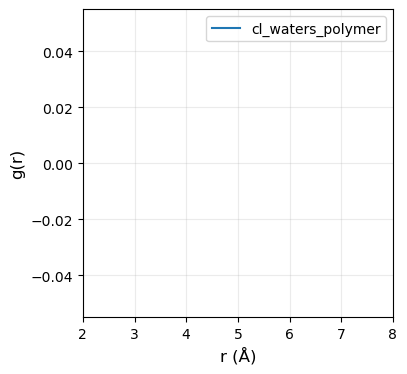

In [6]:
cl_waters = u.select_atoms('(type OW) and (around 5 group cl)', cl=cl, updating=True)
polymer = u.select_atoms('(resname PA*) and (not element H)')
rdf = InterRDF(cl_waters, polymer, nbins=nbins, range=r_range, exclusion_block=(1,1), verbose=False)
rdf.run(start=start, stop=stop, step=step, backend='multiprocessing', n_workers=16)
df[f'rdf_cl_waters_polymer'] = rdf.results.rdf
df[f'count_cl_waters_polymer'] = rdf.results.count

plot_rdf(df, 'r_A', 'rdf_cl_waters_polymer')

/Users/nate_schwindt/anaconda3/envs/aem/lib/python3.13/site-packages/MDAnalysis/analysis/rdf.py:401: RuntimeWarning: invalid value encountered in divide
  self.results.rdf = self.results.count / norm
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_7597/2692790122.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_cl_waters_ca'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_7597/2692790122.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_cl_waters_ca'] = rdf.result

<Axes: xlabel='r (Å)', ylabel='g(r)'>

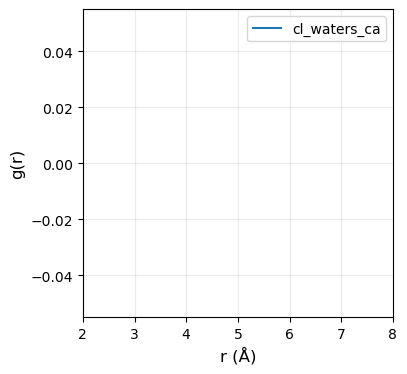

In [7]:
rdf = InterRDF(cl_waters, ca, nbins=nbins, range=r_range, exclusion_block=(1,1), verbose=False)
rdf.run(start=start, stop=stop, step=step, backend='multiprocessing', n_workers=16)
df[f'rdf_cl_waters_ca'] = rdf.results.rdf
df[f'count_cl_waters_ca'] = rdf.results.count

plot_rdf(df, 'r_A', 'rdf_cl_waters_ca')

/Users/nate_schwindt/anaconda3/envs/aem/lib/python3.13/site-packages/MDAnalysis/analysis/rdf.py:401: RuntimeWarning: invalid value encountered in divide
  self.results.rdf = self.results.count / norm
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_7597/2694251729.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_cl_waters_amide_o'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_7597/2694251729.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_cl_waters_amide_o'] = 

<Axes: xlabel='r (Å)', ylabel='g(r)'>

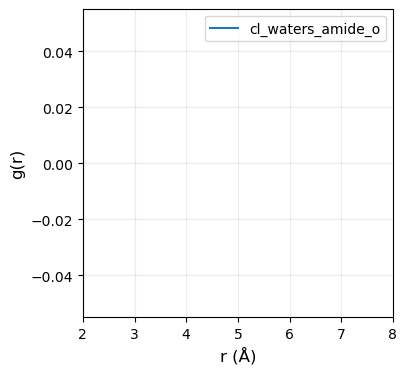

In [8]:
rdf = InterRDF(cl_waters, amide_o, nbins=nbins, range=r_range, exclusion_block=(1,1), verbose=False)
rdf.run(start=start, stop=stop, step=step, backend='multiprocessing', n_workers=16)
df[f'rdf_cl_waters_amide_o'] = rdf.results.rdf
df[f'count_cl_waters_amide_o'] = rdf.results.count

plot_rdf(df, 'r_A', 'rdf_cl_waters_amide_o')

/Users/nate_schwindt/anaconda3/envs/aem/lib/python3.13/site-packages/MDAnalysis/analysis/rdf.py:401: RuntimeWarning: invalid value encountered in divide
  self.results.rdf = self.results.count / norm
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_7597/1202450701.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_cl_waters_coo_o'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_7597/1202450701.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_cl_waters_coo_o'] = rdf.

<Axes: xlabel='r (Å)', ylabel='g(r)'>

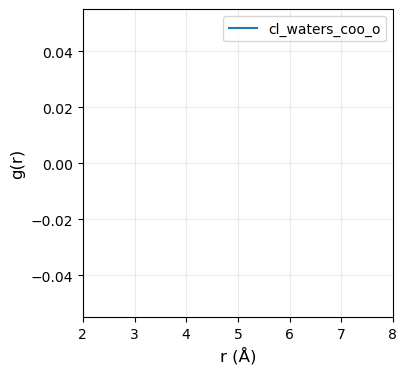

In [9]:
rdf = InterRDF(cl_waters, coo_o, nbins=nbins, range=r_range, exclusion_block=(1,1), verbose=False)
rdf.run(start=start, stop=stop, step=step, backend='multiprocessing', n_workers=16)
df[f'rdf_cl_waters_coo_o'] = rdf.results.rdf
df[f'count_cl_waters_coo_o'] = rdf.results.count

plot_rdf(df, 'r_A', 'rdf_cl_waters_coo_o')

### Cl - polymer

/Users/nate_schwindt/anaconda3/envs/aem/lib/python3.13/site-packages/MDAnalysis/analysis/rdf.py:401: RuntimeWarning: invalid value encountered in divide
  self.results.rdf = self.results.count / norm
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_7597/3430391733.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_cl_polymer'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_7597/3430391733.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_cl_polymer'] = rdf.results.co

(0.0, 10.0)

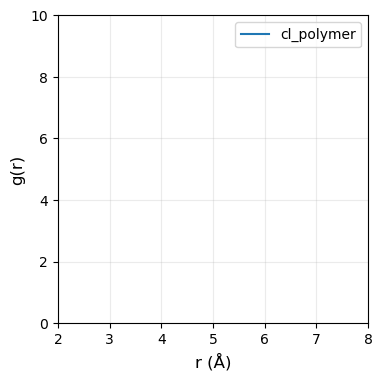

In [10]:
polymer = u.select_atoms('(resname PA*) and (not element H)')
rdf = InterRDF(cl, polymer, nbins=nbins, range=r_range, exclusion_block=(1,1), verbose=False)
rdf.run(start=start, stop=stop, step=step, backend='multiprocessing', n_workers=16)
df[f'rdf_cl_polymer'] = rdf.results.rdf
df[f'count_cl_polymer'] = rdf.results.count

plot_rdf(df, 'r_A', 'rdf_cl_polymer')
plt.ylim(0, 10)

(0.0, 10.0)

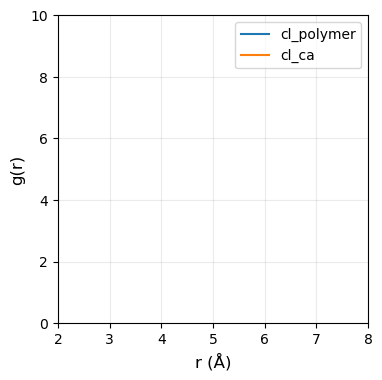

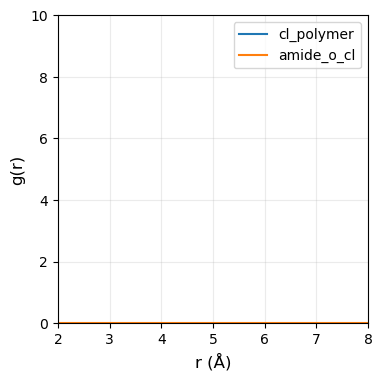

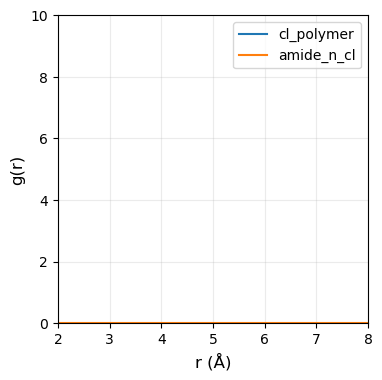

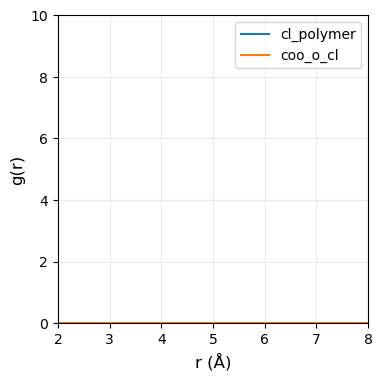

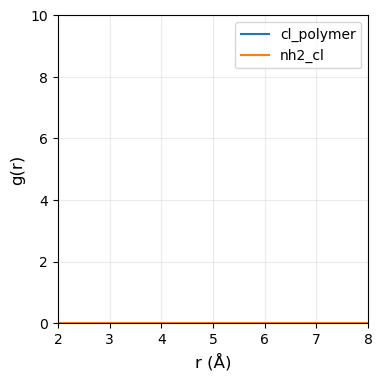

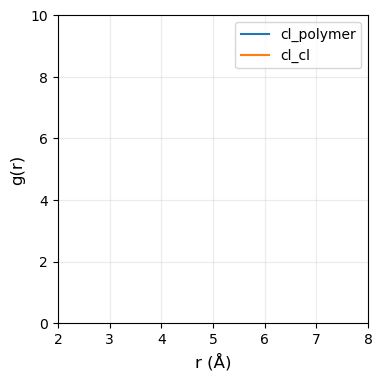

In [11]:
fig, ax = plt.subplots(figsize=(4, 4))
ax = plot_rdf(df, 'r_A', 'rdf_cl_polymer', ax=ax)
ax = plot_rdf(df, 'r_A', 'rdf_cl_ca', ax=ax)
plt.ylim(0, 10)

fig, ax = plt.subplots(figsize=(4, 4))
ax = plot_rdf(df, 'r_A', 'rdf_cl_polymer', ax=ax)
ax = plot_rdf(df, 'r_A', 'rdf_amide_o_cl', ax=ax)
plt.ylim(0, 10)

fig, ax = plt.subplots(figsize=(4, 4))
ax = plot_rdf(df, 'r_A', 'rdf_cl_polymer', ax=ax)
ax = plot_rdf(df, 'r_A', 'rdf_amide_n_cl', ax=ax)
plt.ylim(0, 10)

fig, ax = plt.subplots(figsize=(4, 4))
ax = plot_rdf(df, 'r_A', 'rdf_cl_polymer', ax=ax)
ax = plot_rdf(df, 'r_A', 'rdf_coo_o_cl', ax=ax)
plt.ylim(0, 10)

fig, ax = plt.subplots(figsize=(4, 4))
ax = plot_rdf(df, 'r_A', 'rdf_cl_polymer', ax=ax)
ax = plot_rdf(df, 'r_A', 'rdf_nh2_cl', ax=ax)
plt.ylim(0, 10)

fig, ax = plt.subplots(figsize=(4, 4))
ax = plot_rdf(df, 'r_A', 'rdf_cl_polymer', ax=ax)
ax = plot_rdf(df, 'r_A', 'rdf_cl_cl', ax=ax)
plt.ylim(0, 10)

### COO O - Polymer

/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_7597/3408249017.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_coo_o_polymer'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_7597/3408249017.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_coo_o_polymer'] = rdf.results.count


(0.0, 10.0)

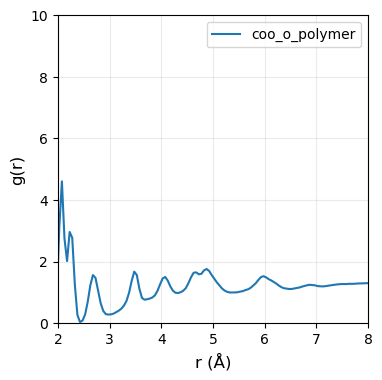

In [12]:
polymer = u.select_atoms('(resname PA*) and (not element H)')
rdf = InterRDF(coo_o, polymer, nbins=nbins, range=r_range, exclusion_block=(1,1), verbose=False)
rdf.run(start=start, stop=stop, step=step, backend='multiprocessing', n_workers=16)
df[f'rdf_coo_o_polymer'] = rdf.results.rdf
df[f'count_coo_o_polymer'] = rdf.results.count

plot_rdf(df, 'r_A', 'rdf_coo_o_polymer')
plt.ylim(0, 10)

### o-p H - polymer

/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_63759/2058806190.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_ha_ortho_para_polymer'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_63759/2058806190.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_ha_ortho_para_polymer'] = rdf.results.count


<Axes: xlabel='r (Å)', ylabel='g(r)'>

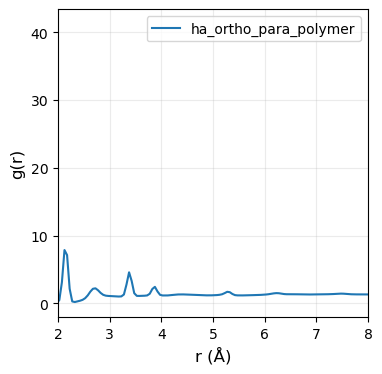

In [11]:
polymer = u.select_atoms('(resname PA*) and (not element H)')
rdf = InterRDF(ha_ortho_para, polymer, nbins=nbins, range=r_range, exclusion_block=(1,1), verbose=False)
rdf.run(start=start, stop=stop, step=step, backend='multiprocessing', n_workers=16)
df[f'rdf_ha_ortho_para_polymer'] = rdf.results.rdf
df[f'count_ha_ortho_para_polymer'] = rdf.results.count

plot_rdf(df, 'r_A', 'rdf_ha_ortho_para_polymer')

### Waters around o-p H - polymer

/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_63759/2170148856.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_ha_waters_polymer'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_63759/2170148856.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_ha_waters_polymer'] = rdf.results.count


<Axes: xlabel='r (Å)', ylabel='g(r)'>

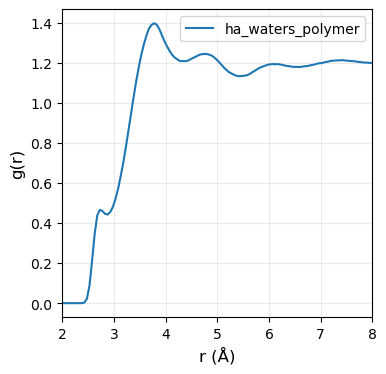

In [6]:
ha_waters = u.select_atoms('(type OW) and (around 5 group ha_ortho_para)', ha_ortho_para=ha_ortho_para, updating=True)
polymer = u.select_atoms('(resname PA*) and (not element H)')
rdf = InterRDF(ha_waters, polymer, nbins=nbins, range=r_range, exclusion_block=(1,1), verbose=False)
rdf.run(start=start, stop=stop, step=step, backend='multiprocessing', n_workers=16)
df[f'rdf_ha_waters_polymer'] = rdf.results.rdf
df[f'count_ha_waters_polymer'] = rdf.results.count

plot_rdf(df, 'r_A', 'rdf_ha_waters_polymer')

/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_63759/122847083.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_ha_waters_ca'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_63759/122847083.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_ha_waters_ca'] = rdf.results.count


<Axes: xlabel='r (Å)', ylabel='g(r)'>

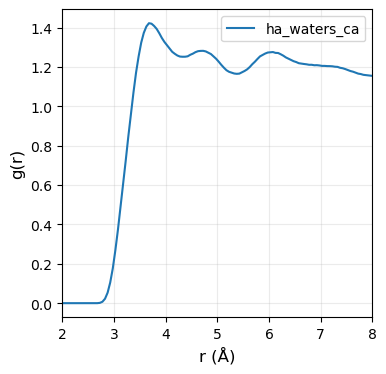

In [7]:
rdf = InterRDF(ha_waters, ca, nbins=nbins, range=r_range, exclusion_block=(1,1), verbose=False)
rdf.run(start=start, stop=stop, step=step, backend='multiprocessing', n_workers=16)
df[f'rdf_ha_waters_ca'] = rdf.results.rdf
df[f'count_ha_waters_ca'] = rdf.results.count

plot_rdf(df, 'r_A', 'rdf_ha_waters_ca')

/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_63759/694146425.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_ha_waters_amide_o'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_63759/694146425.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_ha_waters_amide_o'] = rdf.results.count


<Axes: xlabel='r (Å)', ylabel='g(r)'>

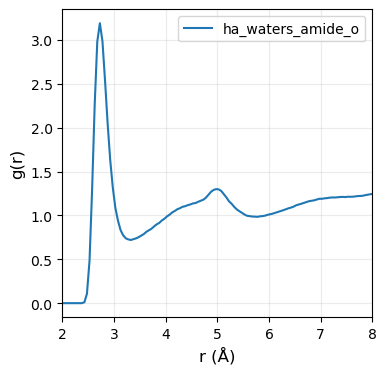

In [8]:
rdf = InterRDF(ha_waters, amide_o, nbins=nbins, range=r_range, exclusion_block=(1,1), verbose=False)
rdf.run(start=start, stop=stop, step=step, backend='multiprocessing', n_workers=16)
df[f'rdf_ha_waters_amide_o'] = rdf.results.rdf
df[f'count_ha_waters_amide_o'] = rdf.results.count

plot_rdf(df, 'r_A', 'rdf_ha_waters_amide_o')

/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_63759/453963307.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'rdf_ha_waters_coo_o'] = rdf.results.rdf
/var/folders/c7/911byk5d5jl0vp7m92bxn01w0000gn/T/ipykernel_63759/453963307.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'count_ha_waters_coo_o'] = rdf.results.count


<Axes: xlabel='r (Å)', ylabel='g(r)'>

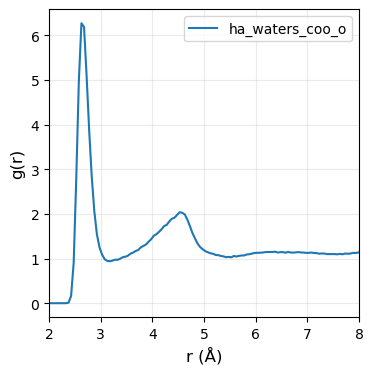

In [9]:
rdf = InterRDF(ha_waters, coo_o, nbins=nbins, range=r_range, exclusion_block=(1,1), verbose=False)
rdf.run(start=start, stop=stop, step=step, backend='multiprocessing', n_workers=16)
df[f'rdf_ha_waters_coo_o'] = rdf.results.rdf
df[f'count_ha_waters_coo_o'] = rdf.results.count

plot_rdf(df, 'r_A', 'rdf_ha_waters_coo_o')

In [12]:
df.to_csv('rdfs.csv', index=False)